In [1]:
# Tham số notebook và thư mục đầu vào.
from pathlib import Path
import os, sys, json, hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT/'pyproject.toml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from scripts.project_evidence import (snapshot, train_workspace, show, style, data_figure,
    feature_figure, baseline_figure, forecast_figure, learning_curve, equity_figure,
    tcn_history_figure, architecture)
from quantstream.features import FEATURES
from quantstream.common import write_json, sha256, utcnow
HISTORY = Path(os.environ.get('QUANTSTREAM_HISTORY_DIR', ROOT/'research_input'))
WORK = ROOT/'notebook_work/portfolio_cpu'
REPORT = ROOT/'reports/portfolio_cpu'
REPORT.mkdir(parents=True, exist_ok=True)
style()
print('Lượt CPU từ snapshot; không kết nối hoặc thay model app đang chạy.')

Lượt CPU từ snapshot; không kết nối hoặc thay model app đang chạy.


In [2]:
# Nạp snapshot và kiểm tra SHA, OHLCV, khóa nến, gap.
bars, source, quality = snapshot(HISTORY)
display(bars.groupby('symbol').agg(candles=('timestamp','size'), first=('timestamp','min'), last=('timestamp','max')))
display(pd.DataFrame([{k:v for k,v in quality.items() if k!='gaps'}]))
display(pd.DataFrame(quality['gaps']))
print('SHA256:', source['bars_sha256'])
print('Nguồn:', source['provider'])
write_json(REPORT/'data_quality.json', quality)
write_json(REPORT/'input_manifest.json', source)

SHA256: 1bc980d79b7a5a9c689883aa8d065e67284d7850d605c353dc2ab040ffb1b653
Nguồn: Binance Spot monthly public archives plus REST


,candles,first,last
symbol,,,
BTCUSDT,33910,2023-01-01 00:00:00+00:00,2026-11-13 23:00:00+00:00
ETHUSDT,33910,2023-01-01 00:00:00+00:00,2026-11-13 23:00:00+00:00


,input_rows,valid_rows,quarantine_rows,duplicate_rows
0,67820,67820,0,0


,symbol,after,missing_bars
0,BTCUSDT,2023-03-24T11:00:00+00:00,2
1,ETHUSDT,2023-03-24T11:00:00+00:00,2


Out[3]: 16884


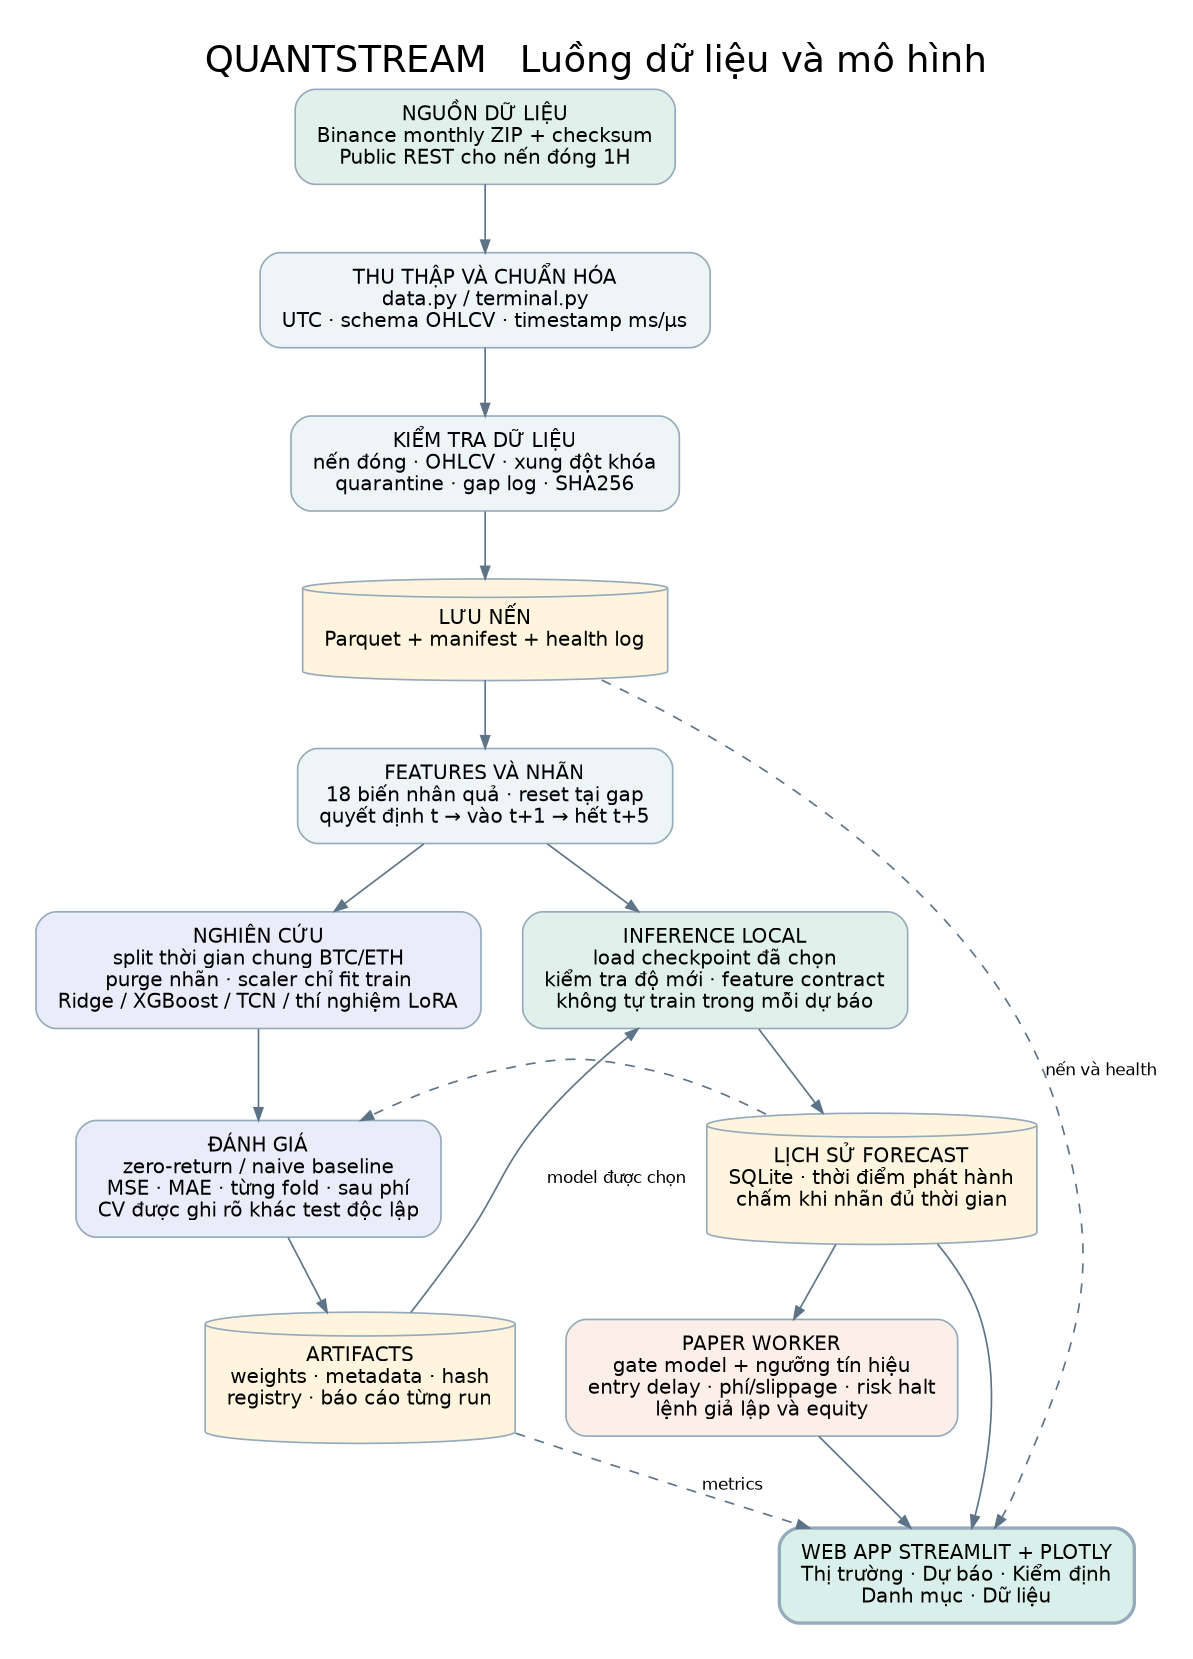

In [3]:
# Sơ đồ các mô-đun và luồng dữ liệu đang có trong source.
display(Image(data=architecture(ROOT), width=1000))
import subprocess
svg = subprocess.run(['dot','-Tsvg',str(ROOT/'docs/architecture.dot')], check=True, capture_output=True).stdout
(REPORT/'architecture.svg').write_bytes(svg)

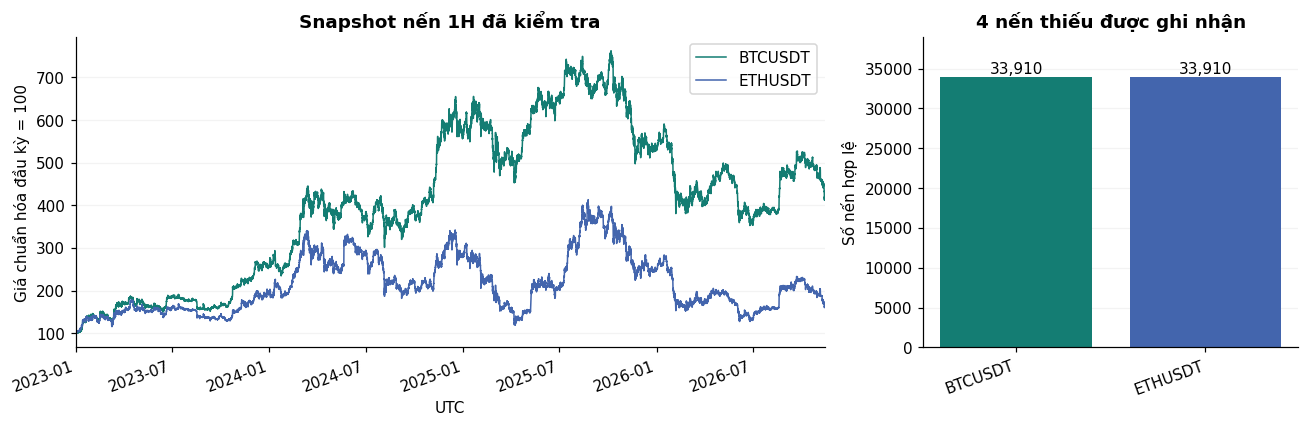

In [4]:
# Giá đầu kỳ = 100 để xem hai tài sản trên cùng thang đo.
show(data_figure(bars, quality))

In [5]:
# Fit thật ba fold Ridge/XGBoost; sau đó refit weights cuối trên mọi nhãn đã biết.
cfg, registry, run, samples, metrics, oof = train_workspace(bars, WORK)
print('Features:', len(FEATURES), FEATURES)
print('Số mẫu fit cuối:', registry['ridge']['training_rows'])
print('Số mẫu OOF/model:', registry['ridge']['validation']['rows'])
print('Validation:', registry['ridge']['validation_start'], '→', registry['ridge']['validation_end'])
print('Runtime fit (giây):', {k:round(v['fit_seconds'],3) for k,v in registry.items()})
metrics.to_csv(REPORT/'validation_metrics.csv', index=False)
rows=[]
for name, meta in registry.items():
    for fold, ratio in enumerate(meta['validation_fold_mse_ratios'],1):
        rows.append({'model':name,'fold':fold,'mse_ratio_to_zero':ratio})
fold_metrics=pd.DataFrame(rows)
fold_metrics.to_csv(REPORT/'fold_metrics.csv', index=False)
write_json(REPORT/'configuration.json', cfg.to_dict())
print('Ngưỡng long:', registry['ridge']['threshold'], '· chưa có final test độc lập.')

Features: 18 ['ret_1', 'ret_4', 'ret_12', 'ret_24', 'vol_12', 'vol_48', 'rsi_14', 'macd', 'atr_14', 'volume_z', 'range_pct', 'body_pct', 'taker_ratio', 'ema_gap', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']
Số mẫu fit cuối: 67608
Số mẫu OOF/model: 1878
Validation: 2026-10-05 07:00:00+00:00 → 2026-11-14 00:00:00+00:00
Runtime fit (giây): {'ridge': 0.098, 'xgboost_d3': 0.941}
Ngưỡng long: 0.006 · chưa có final test độc lập.


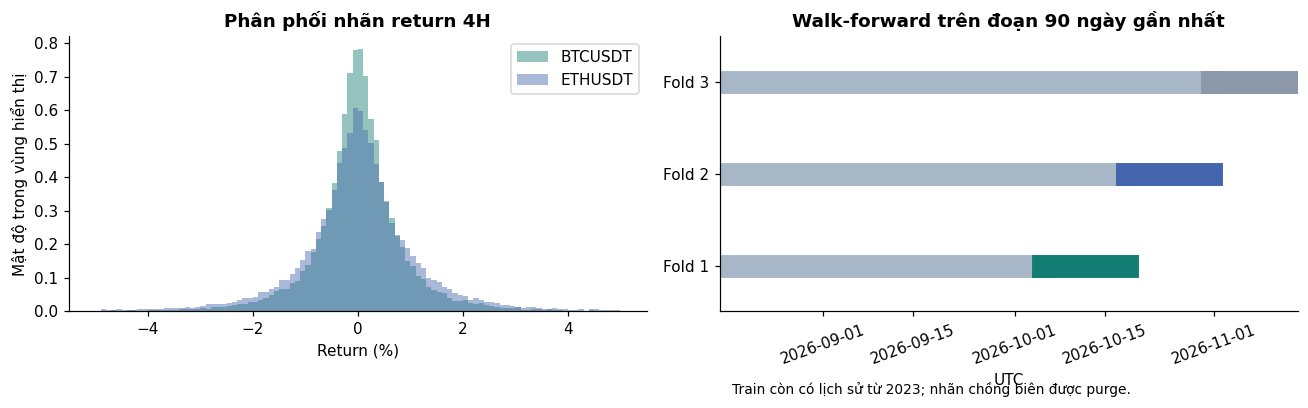

,rows,first,last_label
fold,,,
0,622,2026-10-05 07:00:00+00:00,2026-10-18 10:00:00+00:00
1,622,2026-10-18 11:00:00+00:00,2026-10-31 14:00:00+00:00
2,634,2026-10-31 15:00:00+00:00,2026-11-14 00:00:00+00:00


In [6]:
# Phân phối nhãn và ranh giới walk-forward.
show(feature_figure(samples, oof))
display(oof[oof.model.eq('ridge')].groupby('fold').agg(rows=('prediction','size'), first=('decision_time','min'), last_label=('label_end_time','max')))

,model,rows,mae,mse,mse_ratio_to_zero,directional_accuracy
0,ridge,1878,0.006204,0.000095,0.994550,0.466986
1,xgboost_d3,1878,0.006181,0.000095,0.998255,0.512780
2,zero_return,1878,0.006170,0.000095,1.000000,0.532481
3,naive_ret4,1878,0.009430,0.000197,2.071623,0.495208


,model,fold,mse_ratio_to_zero
0,ridge,1,0.986099
1,ridge,2,1.022540
2,ridge,3,0.983575
3,xgboost_d3,1,1.010488
4,xgboost_d3,2,1.010154
5,xgboost_d3,3,0.983918


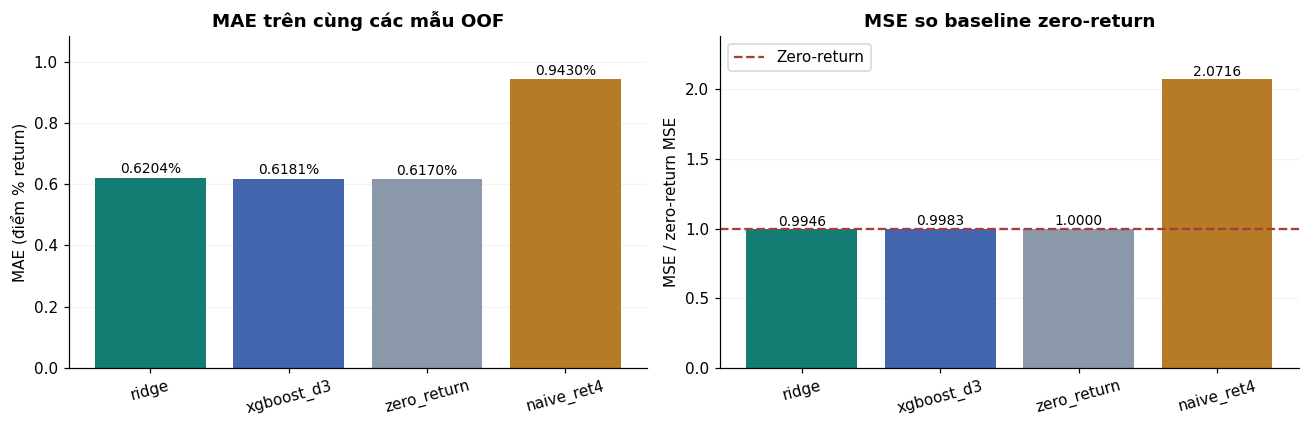

In [7]:
# So sánh Ridge, XGBoost, zero-return và naive_ret4 trên cùng cohort.
display(metrics.round(6))
display(fold_metrics.round(6))
show(baseline_figure(metrics))

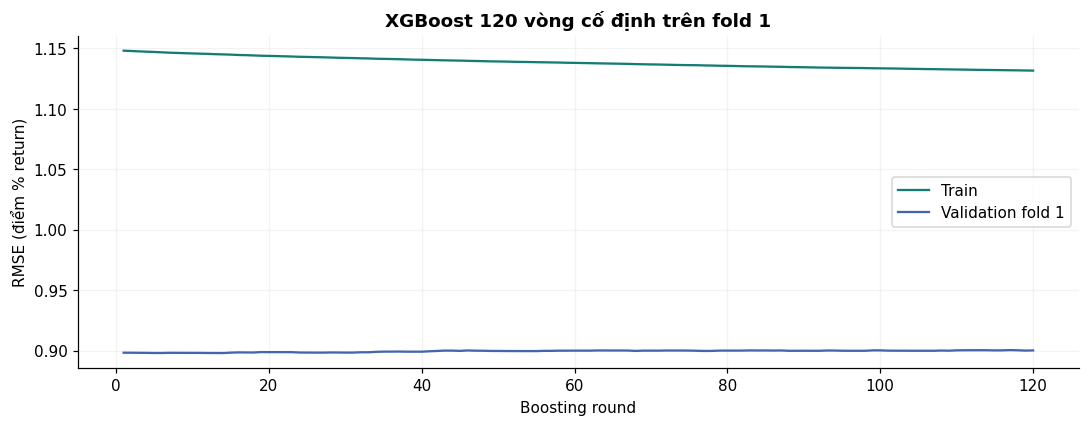

In [8]:
# Lượt chẩn đoán riêng với 120 rounds cố định; không chọn epoch từ outer validation.
learning, figure = learning_curve(bars, samples, oof, cfg)
learning.to_csv(REPORT/'xgboost_learning_curve.csv',index=False)
show(figure)

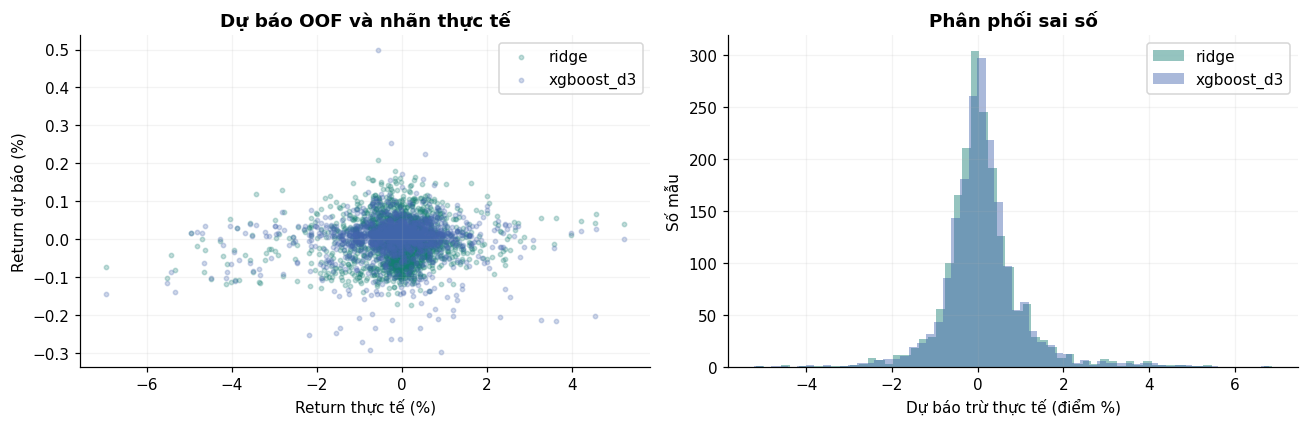

In [9]:
# Dự báo được tạo trước khi refit cuối, không dùng weights cuối để chấm lại OOF.
show(forecast_figure(oof))

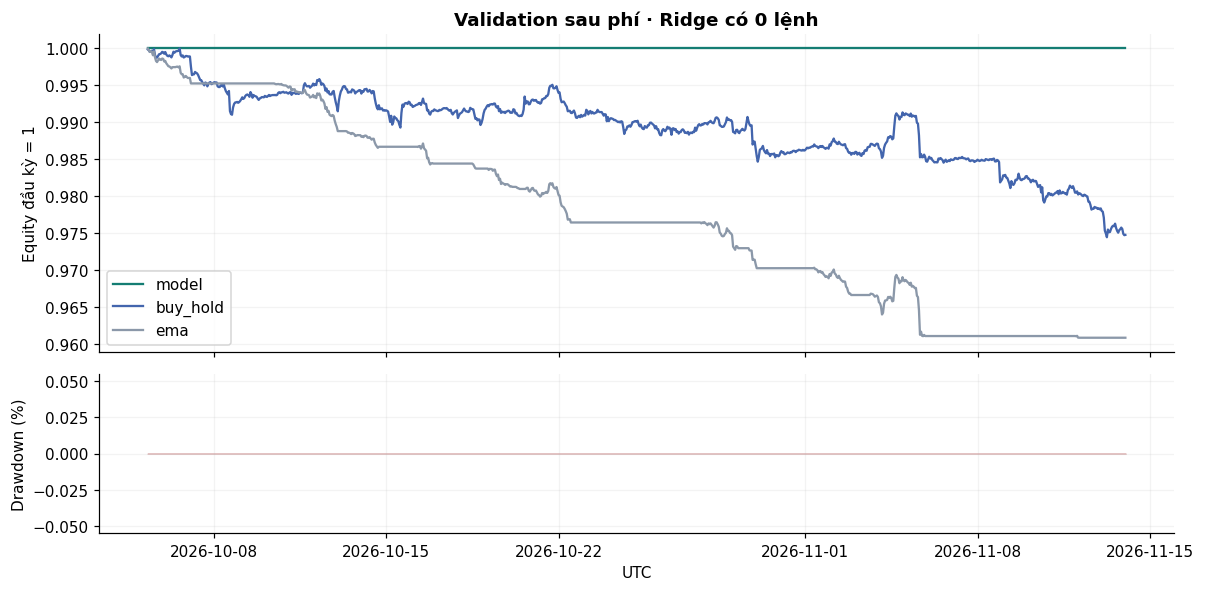

,total_return,max_drawdown,trades,turnover
strategy,0.0,0.0,0,0.0
buy_hold,-0.025228,-0.025543,2,0.349494
ema,-0.039141,-0.039141,154,30.143941


In [10]:
# Backtest cùng cấu hình phí/slippage, giữ riêng với kết quả dự báo.
figure, backtest = equity_figure(run)
show(figure)
display(pd.DataFrame(backtest).T[['total_return','max_drawdown','trades','turnover']])
write_json(REPORT/'ridge_backtest.json',backtest)

,model,alpha,scaler,n_estimators,max_depth,learning_rate,reg_lambda
0,ridge,10.0,StandardScaler,NaN,NaN,NaN,NaN
1,xgboost_d3,NaN,NaN,120.0,3.0,0.04,10.0


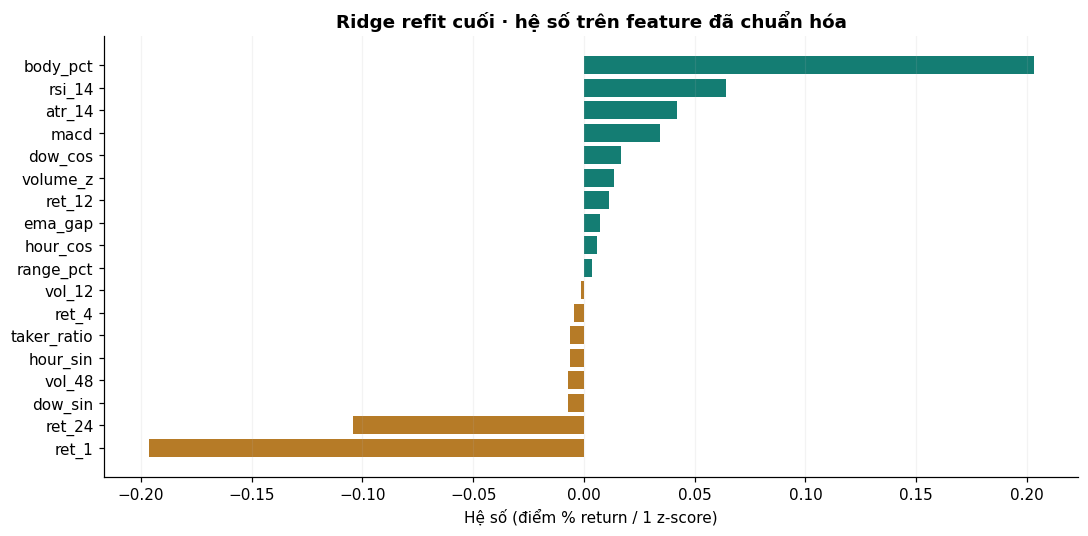

In [11]:
# Siêu tham số thật trong checkpoint CPU vừa fit.
import joblib
model=joblib.load(WORK/registry['ridge']['path'])['model']
weights=pd.DataFrame({'feature':FEATURES,'coefficient_standardized':model.named_steps['ridge'].coef_})
weights.to_csv(REPORT/'ridge_coefficients.csv',index=False)
display(pd.DataFrame([{'model':'ridge','alpha':model.named_steps['ridge'].alpha,'scaler':'StandardScaler'},
                     {'model':'xgboost_d3','n_estimators':120,'max_depth':3,'learning_rate':0.04,'reg_lambda':10}]))
values=weights.sort_values('coefficient_standardized')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(values.feature,values.coefficient_standardized*100,color=['#147d73' if x>=0 else '#b67b27' for x in values.coefficient_standardized])
ax.set(title='Ridge refit cuối · hệ số trên feature đã chuẩn hóa',xlabel='Hệ số (điểm % return / 1 z-score)')
ax.grid(axis='x',alpha=.15);fig.tight_layout();show(fig)

TCN dùng 4 causal blocks, dilation 1/2/4/8, GELU và residual; log này thuộc reference run cũ.


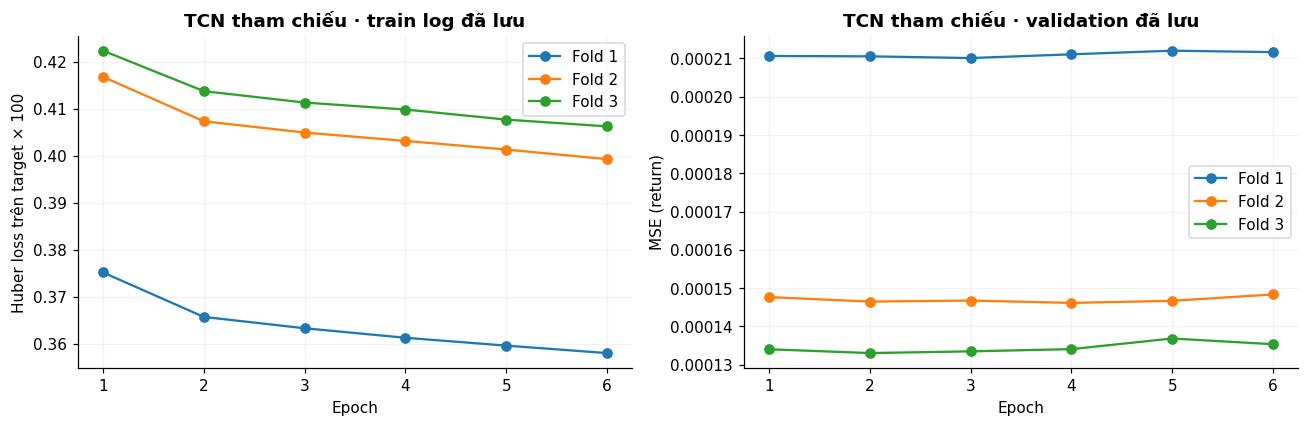

In [12]:
# Log TCN tham chiếu được vẽ lại từ artifact lịch sử, không train TCN trong lượt này.
tcn_log, figure=tcn_history_figure(ROOT)
tcn_log.to_csv(REPORT/'historical_tcn_training_log.csv',index=False)
show(figure)
print('TCN dùng 4 causal blocks, dilation 1/2/4/8, GELU và residual; log này thuộc reference run cũ.')

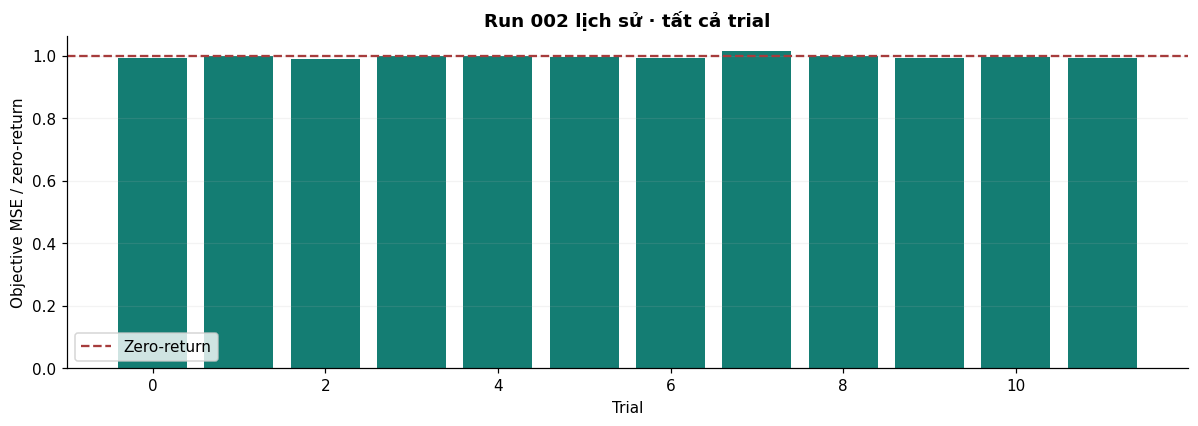

,number,params_family,value,state
0,0,ridge,0.993923,COMPLETE
1,1,xgboost,0.999360,COMPLETE
2,2,tcn,0.988081,COMPLETE
3,3,gru,1.000020,COMPLETE
4,4,tcn,1.000380,COMPLETE
5,5,tcn,0.996360,COMPLETE
6,6,tcn,0.994013,COMPLETE
7,7,xgboost,1.013645,COMPLETE
8,8,gru,0.999634,COMPLETE
9,9,ridge,0.993824,COMPLETE


In [13]:
# Toàn bộ 12 trial Run 002 đã lưu; không chạy lại Optuna để thay kết quả cũ.
trials=pd.read_csv(ROOT/'reports/experiments/run-002-model-search/trials.csv')
fig,ax=plt.subplots(figsize=(11,4))
ax.bar(trials.number,trials.value,color='#147d73')
ax.axhline(1,color='#a63c3c',ls='--',label='Zero-return')
ax.set(title='Run 002 lịch sử · tất cả trial',xlabel='Trial',ylabel='Objective MSE / zero-return')
ax.legend();ax.grid(axis='y',alpha=.15);fig.tight_layout();show(fig)
display(trials[['number','params_family','value','state']].round(6))

,model,rows,mse_ratio_to_zero,mae_pct,directional_accuracy_pct,long_signals_over_060pct
0,ridge,1878,0.996099,0.665806,46.592119,0
1,xgboost_d3,1878,0.999129,0.662478,52.289670,0


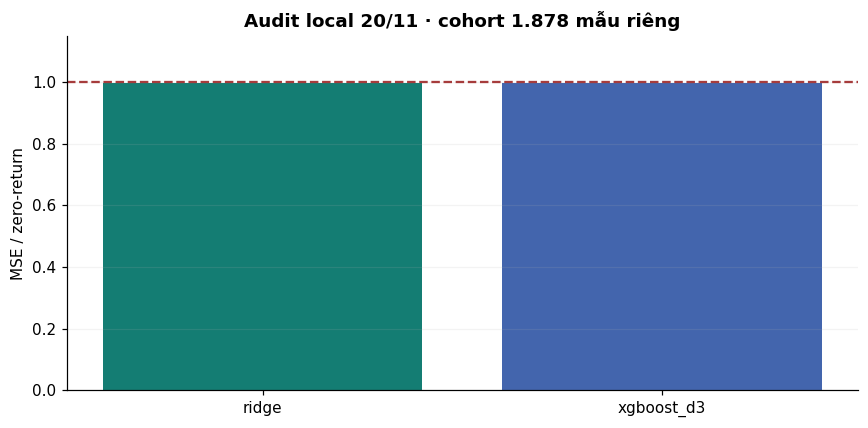

In [14]:
# Lần audit 20/11 có kỳ nhãn khác lượt CPU vừa chạy; đọc và trình bày riêng.
audit=pd.read_csv(ROOT/'reports/experiments/local-validation-20261120/summary.csv')
display(audit[['model','rows','mse_ratio_to_zero','mae_pct','directional_accuracy_pct','long_signals_over_060pct']].round(6))
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(audit.model,audit.mse_ratio_to_zero,color=['#147d73','#4365ad'])
ax.axhline(1,color='#a63c3c',ls='--');ax.set_ylim(0,1.15)
ax.set(title='Audit local 20/11 · cohort 1.878 mẫu riêng',ylabel='MSE / zero-return')
ax.grid(axis='y',alpha=.15);fig.tight_layout();show(fig)

In [15]:
# Lưu dấu vết nguồn, thông số và trạng thái chạy.
import importlib.metadata, xgboost
runtime={'python':sys.version.split()[0], 'packages':{name:importlib.metadata.version(name) for name in ['numpy','pandas','pyarrow','scikit-learn','matplotlib']}}
runtime['packages']['xgboost']=xgboost.__version__
proof={'runtime':runtime,'executed_at_utc':utcnow(),'mode':'actual_cpu_fit_on_saved_snapshot',
       'source_baseline_commit':'9013b2c52806ed299c9539d25f23d514f7eb009a',
       'input_bars_sha256':source['bars_sha256'],'raw_rows':len(bars),
       'training_rows':registry['ridge']['training_rows'],'oof_rows_per_model':registry['ridge']['validation']['rows'],
       'validation_start':registry['ridge']['validation_start'],'validation_end':registry['ridge']['validation_end'],
       'code_sha256':{str(p.relative_to(ROOT)):sha256(p) for p in [ROOT/'quantstream/features.py',ROOT/'quantstream/terminal.py',ROOT/'quantstream/backtest.py',ROOT/'scripts/project_evidence.py']},
       'models':{k:{field:v[field] for field in ['sha256','training_rows','validation','validation_fold_mse_ratios','deployment_status','fit_seconds']} for k,v in registry.items()},
       'new_xgboost_diagnostic_fit_rounds':120,'new_tcn_training':False,'new_gpu_training':False,
       'independent_final_test':False,'source_snapshot':'saved Binance research history; no fresh download in this run'}
write_json(REPORT/'execution.json',proof)
print('Đã lưu metrics, model hashes, input hash và code hashes.')
print('Kết quả thuộc validation đã quan sát; không nâng model lên trạng thái giao dịch tiền thật.')

Đã lưu metrics, model hashes, input hash và code hashes.
Kết quả thuộc validation đã quan sát; không nâng model lên trạng thái giao dịch tiền thật.
